<a href="https://colab.research.google.com/github/usumakikai8-bot/DNN4/blob/main/DNN5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#概要

In [38]:
#DNN(最も簡単なDNN（MLP）による鋼材断面カタログ値の推論)を改良して入力特徴量を増やしたものをDNN2とする。
#DNN2のboxの損失の重みを2倍にする。それ以外は、DNN2を変えない。
#evaluateを変更して、正確度(Accuracy)を詳細に出力できるようにした。

正規化をx_minとx_maxではなく、カタログから恣意的に決めてそのリストを用いる。

北川　元輝さんからもらった3階建ての最適化データとカタログを用いて学習する。→ファイルの表記に対応するようにコードを修正する必要がある。


#github

In [39]:
# !git config --global user.name "usumakikai8-bot"
# !git config --global user.email "usumakikai8@gmail.com"

#第1段階セル（ライブラリのインポート、マウント、設定）

In [40]:
# ライブラリのインポート
import csv
import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset


In [41]:
#google driveのマウント
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
%pwd

'/content/drive/My Drive/research/DNN5'

In [43]:
# Drive 上の作業フォルダ。必要なときだけ変更してください。
%cd /content/drive/MyDrive/research/DNN5


/content/drive/MyDrive/research/DNN5


In [44]:
%pwd

'/content/drive/MyDrive/research/DNN5'

path設定は非常に重要だ。フォルダ構成に注意する。

In [45]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()
# Colab: dataset3 と catalog を Google Drive に配置してください。
DATASET_ROOT = Path('/content/drive/MyDrive/research/dataset3')
CATALOG_ROOT = DATASET_ROOT / 'catalog'
OUTPUT_DIR = PROJECT_ROOT / 'dnn_result'
print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATASET_ROOT:', DATASET_ROOT)
print('CATALOG_ROOT:', CATALOG_ROOT)
print('OUTPUT_DIR:', OUTPUT_DIR)

PROJECT_ROOT: /content/drive/MyDrive/research/DNN5
DATASET_ROOT: /content/drive/MyDrive/research/dataset3
CATALOG_ROOT: /content/drive/MyDrive/research/dataset3/catalog
OUTPUT_DIR: /content/drive/MyDrive/research/DNN5/dnn_result


In [46]:
SEED = 42
BATCH_SIZE = 32
EPOCHS = 500
PATIENCE = 60
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
MAX_SPANS = 10
MIN_SPAN_MM = 4000.0  # 北川さんのPDFを確認後に根拠と値を照合してください
MAX_SPAN_MM_NORMALIZATION = 12000.0
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'{DEVICE=}')
missing = [str(DATASET_ROOT / s) for s in ('train', 'val', 'test') if not (DATASET_ROOT / s).is_dir()]
if missing: raise FileNotFoundError(f'train/val/test が見つかりません: {missing}')
if not CATALOG_ROOT.is_dir():
    raise FileNotFoundError(f'カタログCSVのフォルダがありません: {CATALOG_ROOT}。梁H形鋼カタログ.csv と 柱角形鋼管カタログ.csv を配置してください。')

DEVICE=device(type='cpu')


#第2セル（各種関数定義、カタログの読み込み）

In [47]:
def seed_everything(seed: int = SEED) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def read_text(path: Path) -> str:
    for encoding in ('utf-8-sig', 'utf-8', 'cp932'):
        try: return path.read_text(encoding=encoding)
        except UnicodeDecodeError: pass
    return path.read_text(encoding='utf-8', errors='replace')

def read_catalog(path: Path, kind: str) -> list[dict]:
    rows = list(csv.DictReader(read_text(path).splitlines()))
    name_col = '断面名'
    cols = ('呼び梁せいH(mm)', '呼び幅B(mm)', '腹板厚tw(mm)', 'フランジ厚tf(mm)') if kind == 'h' else ('呼び柱径D(mm)', '板厚t(mm)')
    if not rows or not {name_col, *cols}.issubset(rows[0]):
        raise ValueError(f'カタログCSVの列が想定と異なります: {path}')
    return [{'name': r[name_col].strip(), 'values': tuple(float(r[c]) for c in cols)} for r in rows]

H_CATALOG = read_catalog(CATALOG_ROOT / '梁H形鋼カタログ.csv', 'h')
BOX_CATALOG = read_catalog(CATALOG_ROOT / '柱角形鋼管カタログ.csv', 'box')
print(f'H catalog: {len(H_CATALOG)}, box catalog: {len(BOX_CATALOG)}')


H catalog: 35, box catalog: 38


#第3セル（データ前処理、データローダーの作成）

In [48]:
#以下の部材の値は使わない。→部材の寸法に関しては正規化していないらしい。
# # カタログ寸法の正規化範囲（参考・カタログ属性用）

# # 柱。パターンB: 余裕を持たせた丸め値を使用する場合（推奨）
# column_normalization_params_rounded = {
#     "呼び柱径D": {"min": 200.0, "max": 600.0},
#     "実柱径D": {"min": 200.0, "max": 600.0},
#     "板厚t": {"min": 5.0, "max": 30.0},
#     "角部半径r": {"min": 10.0, "max": 75.0},
#     "断面積": {"min": 5000.0, "max": 60000.0},
#     "単位重量": {"min": 40.0, "max": 450.0},
# }

# # 梁。パターンB: 余裕を持たせた丸め値を使用する場合（推奨）
# beam_norm_params_rounded = {
#     "呼び梁深さH": {"min": 100.0, "max": 1000.0},
#     "呼び幅B": {"min": 50.0, "max": 450.0},
#     "実梁深さH": {"min": 100.0, "max": 1000.0},
#     "実幅B": {"min": 50.0, "max": 450.0},
#     "腹板厚tw": {"min": 5.0, "max": 25.0},
#     "フランジ厚t2": {"min": 5.0, "max": 40.0},
#     "角部半径r": {"min": 5.0, "max": 25.0},
#     "断面積": {"min": 1000.0, "max": 40000.0},
#     "単位重量": {"min": 10.0, "max": 300.0},
# }

In [50]:
FILENAME_RE = re.compile(r'^(?P<id>[0-9]+)_(?P<floor>[0-9]+)階_X(?P<nx>[0-9]+)_Y(?P<ny>[0-9]+)_荷重(?P<load>[0-9.]+)(?: \(\d+\))?\.csv$')

def table_after_marker(text: str, marker: str):
    lines=text.splitlines()
    try:
        start=next(i for i,line in enumerate(lines) if line.strip()==marker)
        data_at=next(i for i in range(start+1,len(lines)) if lines[i].strip()=='<data>')
    except StopIteration as exc: raise ValueError(f'{marker} または <data> がありません') from exc
    header=next(csv.reader([lines[data_at-1]])); rows=[]
    for line in lines[data_at+1:]:
        if not line.strip() or line.strip().startswith('name='): break
        rows.append(next(csv.reader([line])))
    return header,rows

def nominal_to_catalog_name(nominal: str, kind: str) -> str:
    name=nominal.strip(); catalog=H_CATALOG if kind=='h' else BOX_CATALOG
    if name not in {r['name'] for r in catalog}: raise ValueError(f'カタログにない断面名です: {name}')
    return name

def parse_targets(path: Path) -> dict[str, tuple[str,str]]:
    text=read_text(path); result={}
    _,rows=table_after_marker(text,'name=柱断面リスト')
    for row in rows:
        floor=row[0].strip()
        for symbol,section in zip(('C1','C2','C3','C4'),row[1:]):
            if section.strip(): result[f'column:{floor}:{symbol}']=('box',nominal_to_catalog_name(section,'box'))
    header,rows=table_after_marker(text,'name=梁断面リスト')
    for row in rows:
        floor=row[0].strip()
        for symbol,section in zip(header[1:],row[1:]):
            if section.strip(): result[f'beam:{floor}:{symbol.strip()}']=('h',nominal_to_catalog_name(section,'h'))
    return result

def features_from_file(path: Path) -> np.ndarray:
    normalized_name = re.sub(r' \(\d+\)(?=\.csv$)', '', path.name)
    m=FILENAME_RE.fullmatch(normalized_name)
    if not m: raise ValueError(f'想定外のファイル名です: {path.name}')
    nx,ny,load,floors=int(m['nx']),int(m['ny']),float(m['load']),int(m['floor'])
    span_header,rows=table_after_marker(read_text(path),'name=スパン割')
    span_cols=[i for i,col in enumerate(span_header) if col.startswith('スパン')]
    spans={r[0].strip():[float(r[i]) for i in span_cols if i<len(r) and r[i].strip()] for r in rows}
    sx,sy=spans['X'],spans['Y']
    if len(sx)!=nx or len(sy)!=ny: raise ValueError(f'ファイル名とスパン割が不一致: {path.name}')
    if min(sx+sy)<MIN_SPAN_MM: raise ValueError(f'最小スパン{MIN_SPAN_MM:g}mm未満: {path.name}')
    if nx>MAX_SPANS or ny>MAX_SPANS: raise ValueError(f'{MAX_SPANS}スパンを超過: {path.name}')
    xl=sx+[0.0]*(MAX_SPANS-len(sx)); yl=sy+[0.0]*(MAX_SPANS-len(sy))
    xm=[1.0]*len(sx)+[0.0]*(MAX_SPANS-len(sx)); ym=[1.0]*len(sy)+[0.0]*(MAX_SPANS-len(sy))
    return np.asarray([nx,ny,load,floors,*xl,*yl,*xm,*ym,float(nx>0),float(ny>0),float(floors>0)],dtype=np.float32)

@dataclass
class Sample:
    file_name: str
    x: np.ndarray
    targets: dict[str,tuple[str,str]]

def load_split(split: str) -> list[Sample]:
    paths=sorted((DATASET_ROOT/split).glob('*.csv'))
    if not paths: raise FileNotFoundError(f'{split} にCSVがありません')
    samples=[Sample(p.name,features_from_file(p),parse_targets(p)) for p in paths]
    print(f'{split}: {len(samples)} files'); return samples

seed_everything()
train_samples,val_samples,test_samples=(load_split(s) for s in ('train','val','test'))
SLOTS=sorted({key for sample in train_samples for key in sample.targets})
SLOT_TYPES=[next(sample.targets[slot][0] for sample in train_samples if slot in sample.targets) for slot in SLOTS]
H_TO_ID={r['name']:i for i,r in enumerate(H_CATALOG)}; BOX_TO_ID={r['name']:i for i,r in enumerate(BOX_CATALOG)}
FEATURE_NORMALIZATION=[(1,10),(1,10),(0,100),(1,20)]+[(MIN_SPAN_MM,MAX_SPAN_MM_NORMALIZATION)]*(2*MAX_SPANS)+[(0,1)]*(2*MAX_SPANS+3)
feature_min=np.asarray([v[0] for v in FEATURE_NORMALIZATION],dtype=np.float32)
feature_max=np.asarray([v[1] for v in FEATURE_NORMALIZATION],dtype=np.float32); feature_range=feature_max-feature_min
class SectionDataset(Dataset):
    def __init__(self,samples): self.samples=samples
    def __len__(self): return len(self.samples)
    def __getitem__(self,index):
        sample=self.samples[index]; yh=[]; yb=[]
        for slot,kind in zip(SLOTS,SLOT_TYPES):
            if slot not in sample.targets: (yh if kind=='h' else yb).append(-100); continue
            _,name=sample.targets[slot]; (yh if kind=='h' else yb).append((H_TO_ID if kind=='h' else BOX_TO_ID)[name])
        x=np.clip((sample.x-feature_min)/feature_range,0.0,1.0)
        x[4+2*MAX_SPANS:4+4*MAX_SPANS]*=np.repeat(x[-3:-1],MAX_SPANS)
        return torch.tensor(x,dtype=torch.float32),torch.tensor(yh,dtype=torch.long),torch.tensor(yb,dtype=torch.long),sample.file_name
train_loader=DataLoader(SectionDataset(train_samples),batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(SectionDataset(val_samples),batch_size=BATCH_SIZE); test_loader=DataLoader(SectionDataset(test_samples),batch_size=BATCH_SIZE)
N_H_SLOTS=sum(k=='h' for k in SLOT_TYPES); N_BOX_SLOTS=sum(k=='box' for k in SLOT_TYPES)
print(f'入力特徴量={len(FEATURE_NORMALIZATION)} (X/Y各10スパン+有効マスク、X/Y/Z方向有無等), 梁slot={N_H_SLOTS}, 柱slot={N_BOX_SLOTS}')

def table_after_marker(text: str, marker: str):
    lines=text.splitlines()
    try:
        start=next(i for i,line in enumerate(lines) if line.strip()==marker)
        data_at=next(i for i in range(start+1,len(lines)) if lines[i].strip()=='<data>')
    except StopIteration as exc: raise ValueError(f'{marker} または <data> がありません') from exc
    header=next(csv.reader([lines[data_at-1]])); rows=[]
    for line in lines[data_at+1:]:
        if not line.strip() or line.strip().startswith('name='): break
        rows.append(next(csv.reader([line])))
    return header,rows

def nominal_to_catalog_name(nominal: str, kind: str) -> str:
    name=nominal.strip(); catalog=H_CATALOG if kind=='h' else BOX_CATALOG
    if name not in {r['name'] for r in catalog}: raise ValueError(f'カタログにない断面名です: {name}')
    return name

def parse_targets(path: Path) -> dict[str, tuple[str,str]]:
    text=read_text(path); result={}
    _,rows=table_after_marker(text,'name=柱断面リスト')
    for row in rows:
        floor=row[0].strip()
        for symbol,section in zip(('C1','C2','C3','C4'),row[1:]):
            if section.strip(): result[f'column:{floor}:{symbol}']=('box',nominal_to_catalog_name(section,'box'))
    header,rows=table_after_marker(text,'name=梁断面リスト')
    for row in rows:
        floor=row[0].strip()
        for symbol,section in zip(header[1:],row[1:]):
            if section.strip(): result[f'beam:{floor}:{symbol.strip()}']=('h',nominal_to_catalog_name(section,'h'))
    return result

def features_from_file(path: Path) -> np.ndarray:
    m=FILENAME_RE.fullmatch(path.name)
    if not m: raise ValueError(f'想定外のファイル名です: {path.name}')
    nx,ny,load,floors=int(m['nx']),int(m['ny']),float(m['load']),int(m['floor'])
    span_header, rows = table_after_marker(read_text(path), 'name=スパン割')
    span_cols = [
        i for i, col in enumerate(span_header)
        if col.startswith('スパン')
    ]
    spans = {
        r[0].strip(): [
            float(r[i]) for i in span_cols
            if i < len(r) and r[i].strip()
        ]
        for r in rows
    }
    sx,sy=spans['X'],spans['Y']
    if len(sx)!=nx or len(sy)!=ny: raise ValueError(f'ファイル名とスパン割が不一致: {path.name}')
    if min(sx+sy)<MIN_SPAN_MM: raise ValueError(f'最小スパン{MIN_SPAN_MM:g}mm未満: {path.name}')
    if nx>MAX_SPANS or ny>MAX_SPANS: raise ValueError(f'{MAX_SPANS}スパンを超過: {path.name}')
    xl=sx+[0.0]*(MAX_SPANS-len(sx)); yl=sy+[0.0]*(MAX_SPANS-len(sy))
    xm=[1.0]*len(sx)+[0.0]*(MAX_SPANS-len(sx)); ym=[1.0]*len(sy)+[0.0]*(MAX_SPANS-len(sy))
    return np.asarray([nx,ny,load,floors,*xl,*yl,*xm,*ym,float(nx>0),float(ny>0),float(floors>0)],dtype=np.float32)

@dataclass
class Sample:
    file_name: str
    x: np.ndarray
    targets: dict[str,tuple[str,str]]

def load_split(split: str) -> list[Sample]:
    paths=sorted((DATASET_ROOT/split).glob('*.csv'))
    if not paths: raise FileNotFoundError(f'{split} にCSVがありません')
    samples=[Sample(p.name,features_from_file(p),parse_targets(p)) for p in paths]
    print(f'{split}: {len(samples)} files'); return samples

seed_everything()
train_samples,val_samples,test_samples=(load_split(s) for s in ('train','val','test'))
SLOTS=sorted({key for sample in train_samples for key in sample.targets})
SLOT_TYPES=[next(sample.targets[slot][0] for sample in train_samples if slot in sample.targets) for slot in SLOTS]
H_TO_ID={r['name']:i for i,r in enumerate(H_CATALOG)}; BOX_TO_ID={r['name']:i for i,r in enumerate(BOX_CATALOG)}
FEATURE_NORMALIZATION=[(1,10),(1,10),(0,100),(1,20)]+[(MIN_SPAN_MM,MAX_SPAN_MM_NORMALIZATION)]*(2*MAX_SPANS)+[(0,1)]*(2*MAX_SPANS+3)
feature_min=np.asarray([v[0] for v in FEATURE_NORMALIZATION],dtype=np.float32)
feature_max=np.asarray([v[1] for v in FEATURE_NORMALIZATION],dtype=np.float32); feature_range=feature_max-feature_min
class SectionDataset(Dataset):
    def __init__(self,samples): self.samples=samples
    def __len__(self): return len(self.samples)
    def __getitem__(self,index):
        sample=self.samples[index]; yh=[]; yb=[]
        for slot,kind in zip(SLOTS,SLOT_TYPES):
            if slot not in sample.targets: (yh if kind=='h' else yb).append(-100); continue
            _,name=sample.targets[slot]; (yh if kind=='h' else yb).append((H_TO_ID if kind=='h' else BOX_TO_ID)[name])
        x=np.clip((sample.x-feature_min)/feature_range,0.0,1.0)
        x[4+2*MAX_SPANS:4+4*MAX_SPANS]*=np.repeat(x[-3:-1],MAX_SPANS)
        return torch.tensor(x,dtype=torch.float32),torch.tensor(yh,dtype=torch.long),torch.tensor(yb,dtype=torch.long),sample.file_name
train_loader=DataLoader(SectionDataset(train_samples),batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(SectionDataset(val_samples),batch_size=BATCH_SIZE); test_loader=DataLoader(SectionDataset(test_samples),batch_size=BATCH_SIZE)
N_H_SLOTS=sum(k=='h' for k in SLOT_TYPES); N_BOX_SLOTS=sum(k=='box' for k in SLOT_TYPES)
print(f'入力特徴量={len(FEATURE_NORMALIZATION)} (X/Y各10スパン+有効マスク、X/Y/Z方向有無等), 梁slot={N_H_SLOTS}, 柱slot={N_BOX_SLOTS}')

def table_after_marker(text: str, marker: str):
    lines=text.splitlines()
    try:
        start=next(i for i,line in enumerate(lines) if line.strip()==marker)
        data_at=next(i for i in range(start+1,len(lines)) if lines[i].strip()=='<data>')
    except StopIteration as exc: raise ValueError(f'{marker} または <data> がありません') from exc
    header=next(csv.reader([lines[data_at-1]])); rows=[]
    for line in lines[data_at+1:]:
        if not line.strip() or line.strip().startswith('name='): break
        rows.append(next(csv.reader([line])))
    return header,rows

def nominal_to_catalog_name(nominal: str, kind: str) -> str:
    name=nominal.strip(); catalog=H_CATALOG if kind=='h' else BOX_CATALOG
    if name not in {r['name'] for r in catalog}: raise ValueError(f'カタログにない断面名です: {name}')
    return name

def parse_targets(path: Path) -> dict[str, tuple[str,str]]:
    text=read_text(path); result={}
    _,rows=table_after_marker(text,'name=柱断面リスト')
    for row in rows:
        floor=row[0].strip()
        for symbol,section in zip(('C1','C2','C3','C4'),row[1:]):
            if section.strip(): result[f'column:{floor}:{symbol}']=('box',nominal_to_catalog_name(section,'box'))
    header,rows=table_after_marker(text,'name=梁断面リスト')
    for row in rows:
        floor=row[0].strip()
        for symbol,section in zip(header[1:],row[1:]):
            if section.strip(): result[f'beam:{floor}:{symbol.strip()}']=('h',nominal_to_catalog_name(section,'h'))
    return result

def features_from_file(path: Path) -> np.ndarray:
    m=FILENAME_RE.fullmatch(path.name)
    if not m: raise ValueError(f'想定外のファイル名です: {path.name}')
    nx,ny,load,floors=int(m['nx']),int(m['ny']),float(m['load']),int(m['floor'])
    span_header,rows=table_after_marker(read_text(path),'name=スパン割')
    span_cols=[i for i,col in enumerate(span_header) if col.startswith('スパン')]
    spans={r[0].strip():[float(r[i]) for i in span_cols if i<len(r) and r[i].strip()] for r in rows}
    sx,sy=spans['X'],spans['Y']
    if len(sx)!=nx or len(sy)!=ny: raise ValueError(f'ファイル名とスパン割が不一致: {path.name}')
    if min(sx+sy)<MIN_SPAN_MM: raise ValueError(f'最小スパン{MIN_SPAN_MM:g}mm未満: {path.name}')
    if nx>MAX_SPANS or ny>MAX_SPANS: raise ValueError(f'{MAX_SPANS}スパンを超過: {path.name}')
    xl=sx+[0.0]*(MAX_SPANS-len(sx)); yl=sy+[0.0]*(MAX_SPANS-len(sy))
    xm=[1.0]*len(sx)+[0.0]*(MAX_SPANS-len(sx)); ym=[1.0]*len(sy)+[0.0]*(MAX_SPANS-len(sy))
    return np.asarray([nx,ny,load,floors,*xl,*yl,*xm,*ym,float(nx>0),float(ny>0),float(floors>0)],dtype=np.float32)

@dataclass
class Sample:
    file_name: str
    x: np.ndarray
    targets: dict[str,tuple[str,str]]

def load_split(split: str) -> list[Sample]:
    paths=sorted((DATASET_ROOT/split).glob('*.csv'))
    if not paths: raise FileNotFoundError(f'{split} にCSVがありません')
    samples=[Sample(p.name,features_from_file(p),parse_targets(p)) for p in paths]
    print(f'{split}: {len(samples)} files'); return samples

seed_everything()
train_samples,val_samples,test_samples=(load_split(s) for s in ('train','val','test'))
SLOTS=sorted({key for sample in train_samples for key in sample.targets})
SLOT_TYPES=[next(sample.targets[slot][0] for sample in train_samples if slot in sample.targets) for slot in SLOTS]
H_TO_ID={r['name']:i for i,r in enumerate(H_CATALOG)}; BOX_TO_ID={r['name']:i for i,r in enumerate(BOX_CATALOG)}
FEATURE_NORMALIZATION=[(1,10),(1,10),(0,100),(1,20)]+[(MIN_SPAN_MM,MAX_SPAN_MM_NORMALIZATION)]*(2*MAX_SPANS)+[(0,1)]*(2*MAX_SPANS+3)
feature_min=np.asarray([v[0] for v in FEATURE_NORMALIZATION],dtype=np.float32)
feature_max=np.asarray([v[1] for v in FEATURE_NORMALIZATION],dtype=np.float32); feature_range=feature_max-feature_min
class SectionDataset(Dataset):
    def __init__(self,samples): self.samples=samples
    def __len__(self): return len(self.samples)
    def __getitem__(self,index):
        sample=self.samples[index]; yh=[]; yb=[]
        for slot,kind in zip(SLOTS,SLOT_TYPES):
            if slot not in sample.targets: (yh if kind=='h' else yb).append(-100); continue
            _,name=sample.targets[slot]; (yh if kind=='h' else yb).append((H_TO_ID if kind=='h' else BOX_TO_ID)[name])
        x=np.clip((sample.x-feature_min)/feature_range,0.0,1.0)
        x[4+2*MAX_SPANS:4+4*MAX_SPANS]*=np.repeat(x[-3:-1],MAX_SPANS)
        return torch.tensor(x,dtype=torch.float32),torch.tensor(yh,dtype=torch.long),torch.tensor(yb,dtype=torch.long),sample.file_name
train_loader=DataLoader(SectionDataset(train_samples),batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(SectionDataset(val_samples),batch_size=BATCH_SIZE); test_loader=DataLoader(SectionDataset(test_samples),batch_size=BATCH_SIZE)
N_H_SLOTS=sum(k=='h' for k in SLOT_TYPES); N_BOX_SLOTS=sum(k=='box' for k in SLOT_TYPES)
print(f'入力特徴量={len(FEATURE_NORMALIZATION)} (X/Y各10スパン+有効マスク、X/Y/Z方向有無等), 梁slot={N_H_SLOTS}, 柱slot={N_BOX_SLOTS}')

def table_after_marker(text: str, marker: str):
    lines=text.splitlines()
    try:
        start=next(i for i,line in enumerate(lines) if line.strip()==marker)
        data_at=next(i for i in range(start+1,len(lines)) if lines[i].strip()=='<data>')
    except StopIteration as exc: raise ValueError(f'{marker} または <data> がありません') from exc
    header=next(csv.reader([lines[data_at-1]])); rows=[]
    for line in lines[data_at+1:]:
        if not line.strip() or line.strip().startswith('name='): break
        rows.append(next(csv.reader([line])))
    return header,rows

def nominal_to_catalog_name(nominal: str, kind: str) -> str:
    name=nominal.strip(); catalog=H_CATALOG if kind=='h' else BOX_CATALOG
    if name not in {r['name'] for r in catalog}: raise ValueError(f'カタログにない断面名です: {name}')
    return name

def parse_targets(path: Path) -> dict[str, tuple[str,str]]:
    text=read_text(path); result={}
    _,rows=table_after_marker(text,'name=柱断面リスト')
    for row in rows:
        floor=row[0].strip()
        for symbol,section in zip(('C1','C2','C3','C4'),row[1:]):
            if section.strip(): result[f'column:{floor}:{symbol}']=('box',nominal_to_catalog_name(section,'box'))
    header,rows=table_after_marker(text,'name=梁断面リスト')
    for row in rows:
        floor=row[0].strip()
        for symbol,section in zip(header[1:],row[1:]):
            if section.strip(): result[f'beam:{floor}:{symbol.strip()}']=('h',nominal_to_catalog_name(section,'h'))
    return result

# def features_from_file(path: Path) -> np.ndarray:
#     m=FILENAME_RE.fullmatch(path.name)
#     if not m: raise ValueError(f'想定外のファイル名です: {path.name}')
#     nx,ny,load,floors=int(m['nx']),int(m['ny']),float(m['load']),int(m['floor'])
#     _,rows=table_after_marker(read_text(path),'name=スパン割')
#     spans={r[0].strip():[float(v) for v in r[1:1+MAX_SPANS] if v.strip()] for r in rows}
#     sx,sy=spans['X'],spans['Y']
#     if len(sx)!=nx or len(sy)!=ny: raise ValueError(f'ファイル名とスパン割が不一致: {path.name}')
#     if min(sx+sy)<MIN_SPAN_MM: raise ValueError(f'最小スパン{MIN_SPAN_MM:g}mm未満: {path.name}')
#     if nx>MAX_SPANS or ny>MAX_SPANS: raise ValueError(f'{MAX_SPANS}スパンを超過: {path.name}')
#     xl=sx+[0.0]*(MAX_SPANS-len(sx)); yl=sy+[0.0]*(MAX_SPANS-len(sy))
#     xm=[1.0]*len(sx)+[0.0]*(MAX_SPANS-len(sx)); ym=[1.0]*len(sy)+[0.0]*(MAX_SPANS-len(sy))
#     return np.asarray([nx,ny,load,floors,*xl,*yl,*xm,*ym,float(nx>0),float(ny>0),float(floors>0)],dtype=np.float32)


def features_from_file(path: Path) -> np.ndarray:
    # ファイル名から建物の諸元を取得
    normalized_name = re.sub(
        r' \(\d+\)(?=\.csv$)', '', path.name
    )
    m = FILENAME_RE.fullmatch(normalized_name)

    if not m:
        raise ValueError(f'想定外のファイル名です: {path.name}')

    nx = int(m['nx'])
    ny = int(m['ny'])
    load = float(m['load'])
    floors = int(m['floor'])

    # スパン割テーブルを取得
    text = read_text(path)
    span_header, rows = table_after_marker(text, 'name=スパン割')

    # 「スパン」で始まる列だけを対象とする
    span_cols = [
        i for i, col in enumerate(span_header)
        if col.strip().startswith('スパン')
    ]

    if not span_cols:
        raise ValueError(
            f'スパン列が見つかりません: {path.name}\n'
            f'ヘッダー: {span_header}'
        )

    spans = {}
    for row in rows:
        if not row or not row[0].strip():
            continue

        direction = row[0].strip()
        values = []

        for i in span_cols:
            if i >= len(row):
                continue

            value = row[i].strip()
            if value:
                try:
                    values.append(float(value))
                except ValueError as exc:
                    raise ValueError(
                        f'スパン値が数値ではありません: '
                        f'{path.name}, 方向={direction}, '
                        f'列={span_header[i]}, 値={value!r}'
                    ) from exc

        spans[direction] = values

    if 'X' not in spans or 'Y' not in spans:
        raise ValueError(
            f'X/Y方向のスパン行が見つかりません: {path.name}\n'
            f'取得した行名: {list(spans.keys())}'
        )

    sx = spans['X']
    sy = spans['Y']

    # 不一致の原因を特定できるエラーメッセージ
    if len(sx) != nx or len(sy) != ny:
        raise ValueError(
            f'ファイル名とスパン割が不一致: {path.name}\n'
            f'ファイル名の指定: X={nx}, Y={ny}\n'
            f'CSVから取得した値: X={len(sx)}個 {sx}, '
            f'Y={len(sy)}個 {sy}\n'
            f'スパン列: {[span_header[i] for i in span_cols]}'
        )

    if nx > MAX_SPANS or ny > MAX_SPANS:
        raise ValueError(
            f'{MAX_SPANS}スパンを超過: {path.name}'
        )

    if min(sx + sy) < MIN_SPAN_MM:
        raise ValueError(
            f'最小スパン{MIN_SPAN_MM:g}mm未満: {path.name}'
        )

    # 固定長の入力特徴量に変換
    xl = sx + [0.0] * (MAX_SPANS - len(sx))
    yl = sy + [0.0] * (MAX_SPANS - len(sy))

    xm = [1.0] * len(sx) + [0.0] * (MAX_SPANS - len(sx))
    ym = [1.0] * len(sy) + [0.0] * (MAX_SPANS - len(sy))

    return np.asarray(
        [
            nx, ny, load, floors,
            *xl, *yl,
            *xm, *ym,
            float(nx > 0),
            float(ny > 0),
            float(floors > 0),
        ],
        dtype=np.float32
    )


@dataclass
class Sample:
    file_name: str
    x: np.ndarray
    targets: dict[str,tuple[str,str]]

def load_split(split: str) -> list[Sample]:
    paths=sorted((DATASET_ROOT/split).glob('*.csv'))
    if not paths: raise FileNotFoundError(f'{split} にCSVがありません')
    samples=[Sample(p.name,features_from_file(p),parse_targets(p)) for p in paths]
    print(f'{split}: {len(samples)} files'); return samples

seed_everything()
train_samples,val_samples,test_samples=(load_split(s) for s in ('train','val','test'))
SLOTS=sorted({key for sample in train_samples for key in sample.targets})
SLOT_TYPES=[next(sample.targets[slot][0] for sample in train_samples if slot in sample.targets) for slot in SLOTS]
H_TO_ID={r['name']:i for i,r in enumerate(H_CATALOG)}; BOX_TO_ID={r['name']:i for i,r in enumerate(BOX_CATALOG)}
FEATURE_NORMALIZATION=[(1,10),(1,10),(0,100),(1,20)]+[(MIN_SPAN_MM,MAX_SPAN_MM_NORMALIZATION)]*(2*MAX_SPANS)+[(0,1)]*(2*MAX_SPANS+3)
feature_min=np.asarray([v[0] for v in FEATURE_NORMALIZATION],dtype=np.float32)
feature_max=np.asarray([v[1] for v in FEATURE_NORMALIZATION],dtype=np.float32); feature_range=feature_max-feature_min
class SectionDataset(Dataset):
    def __init__(self,samples): self.samples=samples
    def __len__(self): return len(self.samples)
    def __getitem__(self,index):
        sample=self.samples[index]; yh=[]; yb=[]
        for slot,kind in zip(SLOTS,SLOT_TYPES):
            if slot not in sample.targets: (yh if kind=='h' else yb).append(-100); continue
            _,name=sample.targets[slot]; (yh if kind=='h' else yb).append((H_TO_ID if kind=='h' else BOX_TO_ID)[name])
        x=np.clip((sample.x-feature_min)/feature_range,0.0,1.0)
        x[4+2*MAX_SPANS:4+4*MAX_SPANS]*=np.repeat(x[-3:-1],MAX_SPANS)
        return torch.tensor(x,dtype=torch.float32),torch.tensor(yh,dtype=torch.long),torch.tensor(yb,dtype=torch.long),sample.file_name
train_loader=DataLoader(SectionDataset(train_samples),batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(SectionDataset(val_samples),batch_size=BATCH_SIZE); test_loader=DataLoader(SectionDataset(test_samples),batch_size=BATCH_SIZE)
N_H_SLOTS=sum(k=='h' for k in SLOT_TYPES); N_BOX_SLOTS=sum(k=='box' for k in SLOT_TYPES)
print(f'入力特徴量={len(FEATURE_NORMALIZATION)} (X/Y各10スパン+有効マスク、X/Y/Z方向有無等), 梁slot={N_H_SLOTS}, 柱slot={N_BOX_SLOTS}')

train: 5200 files
val: 1113 files
test: 1115 files
入力特徴量=47 (X/Y各10スパン+有効マスク、X/Y/Z方向有無等), 梁slot=32, 柱slot=16
train: 5200 files
val: 1113 files
test: 1115 files
入力特徴量=47 (X/Y各10スパン+有効マスク、X/Y/Z方向有無等), 梁slot=32, 柱slot=16
train: 5200 files
val: 1113 files
test: 1115 files
入力特徴量=47 (X/Y各10スパン+有効マスク、X/Y/Z方向有無等), 梁slot=32, 柱slot=16
train: 5200 files
val: 1113 files
test: 1115 files
入力特徴量=47 (X/Y各10スパン+有効マスク、X/Y/Z方向有無等), 梁slot=32, 柱slot=16


# モデル次元: 入力=4基本条件+X/Y各10スパン長+各10有効マスク+X/Y/Z部材有無。
# 128は隠れ層ユニット数、出力slot数×カタログ数はslotごとの候補断面スコア。
# 部材がないslotは教師ラベル-100にして損失計算から除外します。

In [51]:
class SimpleDNN(nn.Module):
    def __init__(self,n_features,n_h_slots,n_box_slots,n_h_catalog,n_box_catalog):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(n_features,128),nn.ReLU(),nn.Linear(128,128),nn.ReLU())
        self.h_head=nn.Linear(128,n_h_slots*n_h_catalog); self.box_head=nn.Linear(128,n_box_slots*n_box_catalog)
        self.n_h_slots=n_h_slots; self.n_h_catalog=n_h_catalog; self.n_box_slots=n_box_slots; self.n_box_catalog=n_box_catalog
    def forward(self,x):
        h=self.net(x)
        return self.h_head(h).view(-1,self.n_h_slots,self.n_h_catalog),self.box_head(h).view(-1,self.n_box_slots,self.n_box_catalog)
model=SimpleDNN(len(FEATURE_NORMALIZATION),N_H_SLOTS,N_BOX_SLOTS,len(H_CATALOG),len(BOX_CATALOG)).to(DEVICE)
H_DIMENSIONS=torch.tensor([r['values'] for r in H_CATALOG],dtype=torch.float32,device=DEVICE)
BOX_DIMENSIONS=torch.tensor([r['values'] for r in BOX_CATALOG],dtype=torch.float32,device=DEVICE)
def section_dimension_mse(logits,targets,dimensions):
    valid=targets.ne(-100)
    if not valid.any(): return logits.sum()*0.0
    expected=logits.softmax(-1)@dimensions; truth=dimensions[targets.clamp_min(0)]
    return ((expected-truth).square().mean(-1)*valid).sum()/valid.sum()
print(model)
print(f'入力={len(FEATURE_NORMALIZATION)} → 128 → 128 → 梁slot×{len(H_CATALOG)} / 柱slot×{len(BOX_CATALOG)} logits')

SimpleDNN(
  (net): Sequential(
    (0): Linear(in_features=47, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
  )
  (h_head): Linear(in_features=128, out_features=1120, bias=True)
  (box_head): Linear(in_features=128, out_features=608, bias=True)
)
入力=47 → 128 → 128 → 梁slot×35 / 柱slot×38 logits


#第5セル（評価関数、学習ループ、グラフ描画）

epoch=001 train_loss=4505.9628 val_loss=3696.9230 val_acc=0.089
epoch=020 train_loss=1691.5199 val_loss=1711.0944 val_acc=0.093
epoch=040 train_loss=1515.8870 val_loss=1472.4121 val_acc=0.100
epoch=060 train_loss=1411.1425 val_loss=1389.1927 val_acc=0.092
epoch=080 train_loss=1347.9600 val_loss=1357.1607 val_acc=0.087
epoch=100 train_loss=1339.7652 val_loss=1358.2530 val_acc=0.091
epoch=120 train_loss=1304.7344 val_loss=1358.5404 val_acc=0.112
epoch=140 train_loss=1276.5946 val_loss=1307.1311 val_acc=0.108
epoch=160 train_loss=1243.4550 val_loss=1253.4836 val_acc=0.113
epoch=180 train_loss=1209.2862 val_loss=1237.9375 val_acc=0.108
epoch=200 train_loss=1175.0372 val_loss=1195.2180 val_acc=0.117
epoch=220 train_loss=1154.7280 val_loss=1185.5342 val_acc=0.120
epoch=240 train_loss=1115.9523 val_loss=1164.9991 val_acc=0.126
epoch=260 train_loss=1109.3494 val_loss=1162.6095 val_acc=0.128
epoch=280 train_loss=1106.1867 val_loss=1143.8465 val_acc=0.128
epoch=300 train_loss=1086.1550 val_loss=

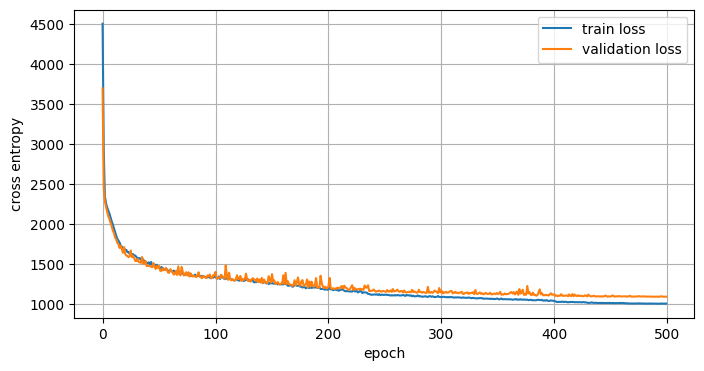

In [52]:
# 1. 評価・推論処理 (evaluate)
# 1. 評価・推論処理 (evaluate)
@torch.no_grad()
def evaluate(loader, export_rows=False):
    model.eval()

    total, correct, full_correct, loss_sum = 0, 0, 0, 0.0

    # 梁・柱の正解数
    h_total, h_correct = 0, 0
    box_total, box_correct = 0, 0

    # 階ごとの正解数
    floor_stats = {}

    records = []

    for x, y_h, y_box, names in loader:
        x, y_h, y_box = x.to(DEVICE), y_h.to(DEVICE), y_box.to(DEVICE)

        logits_h, logits_box = model(x)

        loss_h = section_dimension_mse(logits_h, y_h, H_DIMENSIONS)
        loss_box = section_dimension_mse(logits_box, y_box, BOX_DIMENSIONS)
        loss = loss_h + loss_box

        pred_h = logits_h.argmax(-1)
        pred_box = logits_box.argmax(-1)

        # --------------------------------
        # 全スロットのAccuracy
        # --------------------------------
        all_pred = torch.cat([pred_h, pred_box], dim=1)
        all_true = torch.cat([y_h, y_box], dim=1)

        valid = all_true.ne(-100)
        matches = all_pred.eq(all_true) & valid
        correct += matches.sum().item()
        total += valid.sum().item()

        # 建物に存在するスロットだけで完全一致を判定
        full_correct += (matches | ~valid).all(1).sum().item()

        # --------------------------------
        # 梁（H）のAccuracy
        # --------------------------------
        h_valid = y_h.ne(-100)
        h_correct += (pred_h.eq(y_h) & h_valid).sum().item()
        h_total += h_valid.sum().item()

        # --------------------------------
        # 柱（BOX）のAccuracy
        # --------------------------------
        box_valid = y_box.ne(-100)
        box_correct += (pred_box.eq(y_box) & box_valid).sum().item()
        box_total += box_valid.sum().item()

        # --------------------------------
        # 階ごとのAccuracy
        # --------------------------------
        for slot_idx, (slot, kind) in enumerate(zip(SLOTS, SLOT_TYPES)):

            # slot名から階を取得
            if ':' in slot:
                floor = slot.split(':')[1]
            else:
                floor = slot

            if floor not in floor_stats:
                floor_stats[floor] = {
                    'correct': 0,
                    'total': 0
                }

            if kind == 'h':
                pred = pred_h[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'h'
                )]

                true = y_h[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'h'
                )]

            else:
                pred = pred_box[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'box'
                )]

                true = y_box[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'box'
                )]

            active = true.ne(-100)
            floor_stats[floor]['correct'] += (pred.eq(true) & active).sum().item()
            floor_stats[floor]['total'] += active.sum().item()

        loss_sum += loss.item() * len(names)

        # --------------------------------
        # CSV出力用データ
        # --------------------------------
        if export_rows:
            for b, name in enumerate(names):

                hi = bi = 0

                for slot, kind in zip(SLOTS, SLOT_TYPES):

                    if kind == 'h':
                        p = pred_h[b, hi].item()
                        t = y_h[b, hi].item()
                        hi += 1
                        catalog = H_CATALOG

                    else:
                        p = pred_box[b, bi].item()
                        t = y_box[b, bi].item()
                        bi += 1
                        catalog = BOX_CATALOG

                    # -100 はその建物に存在しないスロットを示すため、出力対象外
                    if t == -100:
                        continue
                    if not (0 <= t < len(catalog)):
                        raise ValueError(
                            f'Invalid target index: file={name}, slot={slot}, '
                            f'target_id={t}, catalog_size={len(catalog)}, type={kind}'
                        )
                    if not (0 <= p < len(catalog)):
                        raise ValueError(
                            f'Invalid prediction index: file={name}, slot={slot}, '
                            f'predicted_id={p}, catalog_size={len(catalog)}, type={kind}'
                        )
                    records.append({
                        'file_name': name,
                        'slot': slot,
                        'section_type': kind,
                        'predicted_catalog': catalog[p]['name'],
                        'true_catalog': catalog[t]['name'],
                        'is_correct': p == t
                    })

    n_files = len(loader.dataset)

    return {
        'loss': loss_sum / n_files,

        # 全体
        'slot_accuracy': correct / max(total, 1),

        # 梁
        'h_accuracy': h_correct / max(h_total, 1),

        # 柱
        'box_accuracy': box_correct / max(box_total, 1),

        # 建物完全一致
        'building_exact_match': full_correct / n_files,

        # 階ごとの統計
        'floor_stats': floor_stats,

        'records': records
    }

# 既存の互換チェックポイントがあればロードし、学習を省略します。
CHECKPOINT_PATH = OUTPUT_DIR / 'best_section_dnn.pt'
CHECKPOINT_SIGNATURE = {
    'feature_normalization': FEATURE_NORMALIZATION,
    'slots': SLOTS,
    'slot_types': SLOT_TYPES,
    'h_catalog': H_CATALOG,
    'box_catalog': BOX_CATALOG,
    'max_spans': MAX_SPANS,
    'min_span_mm': MIN_SPAN_MM,
}
reuse_checkpoint = False
if CHECKPOINT_PATH.exists():
    try:
        cached = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
        reuse_checkpoint = cached.get('checkpoint_signature') == CHECKPOINT_SIGNATURE
        if reuse_checkpoint:
            model.load_state_dict(cached['model_state_dict'])
            print(f'互換チェックポイントを読み込み、学習をスキップしました: {CHECKPOINT_PATH}')
        else:
            print('チェックポイントの構成が現在のデータ/モデルと異なるため再学習します。')
    except Exception as exc:
        print(f'チェックポイントを読み込めないため再学習します: {exc}')
if not reuse_checkpoint:
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=15)
    best_state, best_val, wait = None, float('inf'), 0
    history = {'train_loss': [], 'val_loss': [], 'val_slot_accuracy': []}

    #3. 学習ループ（Training Loop）
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = 0.0
        for x, y_h, y_box, _ in train_loader:
            x, y_h, y_box = x.to(DEVICE), y_h.to(DEVICE), y_box.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits_h, logits_box = model(x)
            #loss = nn.functional.cross_entropy(logits_h.transpose(1, 2), y_h) + nn.functional.cross_entropy(logits_box.transpose(1, 2), y_box)
                    # H梁とBOX柱の損失を別々に計算
            loss_h = section_dimension_mse(logits_h, y_h, H_DIMENSIONS)
            loss_box = section_dimension_mse(logits_box, y_box, BOX_DIMENSIONS)
            loss = loss_h + loss_box
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * len(x)
        val = evaluate(val_loader)
        train_loss /= len(train_loader.dataset)
        scheduler.step(val['loss'])
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val['loss'])
        history['val_slot_accuracy'].append(val['slot_accuracy'])
        if val['loss'] < best_val:
            best_val, wait = val['loss'], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if epoch == 1 or epoch % 20 == 0:
            print(f'epoch={epoch:03d} train_loss={train_loss:.4f} val_loss={val["loss"]:.4f} val_acc={val["slot_accuracy"]:.3f}')
        if wait >= PATIENCE:
            print(f'Early stopping at epoch {epoch}; best val loss={best_val:.4f}')
            break


#4. 最良モデルの復元と学習曲線のプロット
if not reuse_checkpoint:
    model.load_state_dict(best_state)
plt.figure(figsize=(8, 4))
plt.plot(history['train_loss'], label='train loss')
plt.plot(history['val_loss'], label='validation loss')
plt.xlabel('epoch'); plt.ylabel('cross entropy'); plt.legend(); plt.grid(); plt.show()

#第6セル（テストデータの評価、ファイル保存）

In [54]:
# 1. テストデータの評価と結果表示
test_result = evaluate(test_loader, export_rows=True)

print("=" * 50)
print("Test Results")
print("=" * 50)

print(f"Loss                  : {test_result['loss']:.4f}")
print(f"Slot Accuracy         : {test_result['slot_accuracy']:.4f}")
print(f"H (Beam) Accuracy     : {test_result['h_accuracy']:.4f}")
print(f"BOX (Column) Accuracy : {test_result['box_accuracy']:.4f}")
print(f"Building Exact Match  : {test_result['building_exact_match']:.4f}")

print("\n" + "=" * 50)
print("Accuracy by Floor")
print("=" * 50)

for floor, stats in test_result['floor_stats'].items():
    accuracy = stats['correct'] / stats['total']
    print(
        f"{floor:>4s} : "
        f"{accuracy:.4f} "
        f"({stats['correct']}/{stats['total']})"
    )

#2. 予測結果のCSVファイルへの書き出し
predictions = pd.DataFrame(test_result['records'])
pred_path = OUTPUT_DIR / 'test_catalog_predictions.csv'
predictions.to_csv(pred_path, index=False, encoding='utf-8-sig')

#3. チェックポイント（学習済みモデル等）の保存
checkpoint = {
    'model_state_dict': model.state_dict(),
    'checkpoint_signature': CHECKPOINT_SIGNATURE,
    'feature_min': feature_min,  # 最小値を保存
    'feature_max': feature_max,
    'feature_normalization': FEATURE_NORMALIZATION,
    'slots': SLOTS,
    'slot_types': SLOT_TYPES,
    'h_catalog': H_CATALOG,
    'box_catalog': BOX_CATALOG,
}
torch.save(checkpoint, CHECKPOINT_PATH)

#4. 完了メッセージと予測結果プレビューの表示
print(f'Saved: {pred_path}')
print(predictions.head(20).to_string(index=False))

Test Results
Loss                  : 1121.5077
Slot Accuracy         : 0.1195
H (Beam) Accuracy     : 0.1701
BOX (Column) Accuracy : 0.0350
Building Exact Match  : 0.0000

Accuracy by Floor
 2FL : 0.1010 (1203/11912)
 3FL : 0.1074 (1279/11912)
 4FL : 0.1437 (859/5976)
 RFL : 0.2139 (1594/7452)
 1FL : 0.0110 (49/4460)
Saved: /content/drive/MyDrive/research/DNN5/dnn_result/test_catalog_predictions.csv
            file_name         slot section_type  predicted_catalog       true_catalog  is_correct
0006_4階_X2_Y3_荷重8.csv beam:2FL:GX1            h H-600x200x11x17x13 H-500x200x10x16x13       False
0006_4階_X2_Y3_荷重8.csv beam:2FL:GX2            h H-600x200x11x17x13 H-500x200x10x16x13       False
0006_4階_X2_Y3_荷重8.csv beam:2FL:GX3            h H-600x200x11x17x13 H-500x200x10x16x13       False
0006_4階_X2_Y3_荷重8.csv beam:2FL:GX4            h H-600x200x11x17x13 H-500x200x10x16x13       False
0006_4階_X2_Y3_荷重8.csv beam:2FL:GY1            h H-600x200x11x17x13 H-500x200x10x16x13       False
0006_4階_X

#第7セル（結果をグラフで可視化）

In [56]:
!pip install japanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 50.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for japanize-matplotlib: filename=japanize_matplotlib-1.1.3-py3-none-any.whl size=4120306 sha256=e40875a76740294d5b544991c309aced338c37b35d398907182092d11bef60bb
  Stored in directory: /root/.cache/pip/wheels/56/8b/41/7c8a47025c6eef46f0b7488f2510fff13e48f1e7d5bf26e21b
Successfully built japanize-matplotlib


In [57]:
import re
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
from google.colab import files
#コード中で、
import japanize_matplotlib

#上書きされたあとで、
japanize_matplotlib.japanize()

異常候補（要確認）: 1115 / 1115


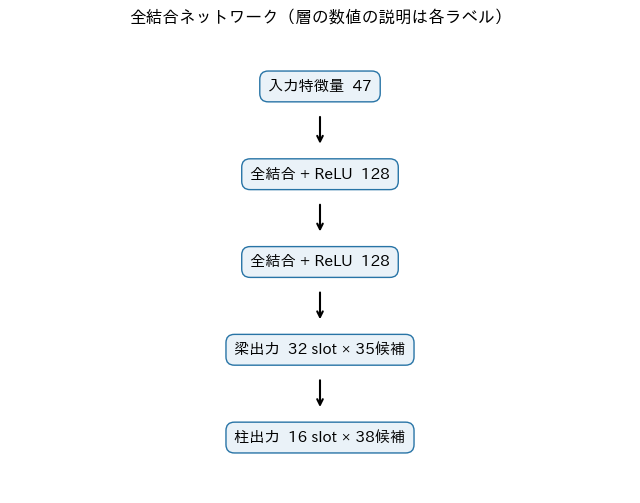

異常候補CSV: /content/drive/MyDrive/research/DNN5/dnn_result/anomaly_candidates.csv


In [58]:
FILENAME_RE = re.compile(r'^(?P<id>[0-9]+)_(?P<floor>[0-9]+)階_X(?P<nx>[0-9]+)_Y(?P<ny>[0-9]+)_荷重(?P<load>[0-9.]+)(?: \(\d+\))?\.csv$')
# 低信頼度、または学習範囲外の入力を異常候補として出力
import os
from IPython.display import display
train_x=np.stack([s.x for s in train_samples]); train_lo=train_x.min(0); train_hi=train_x.max(0)
input_x=np.stack([s.x for s in test_samples]); outside=((input_x<train_lo)|(input_x>train_hi)).any(1)
conf_by_file={}; model.eval()
with torch.no_grad():
    for x,yh,yb,names in test_loader:
        ph,pb=model(x.to(DEVICE))
        for i,name in enumerate(names):
            probs=[]
            if yh.shape[1]: probs.extend(ph[i].softmax(-1).max(-1).values.cpu().tolist())
            if yb.shape[1]: probs.extend(pb[i].softmax(-1).max(-1).values.cpu().tolist())
            conf_by_file[name]=min(probs) if probs else 1.0
anomaly=pd.DataFrame({'file_name':[s.file_name for s in test_samples], 'min_slot_confidence':[conf_by_file[s.file_name] for s in test_samples], 'outside_train_feature_range':outside})
anomaly['anomaly_candidate']=(anomaly.min_slot_confidence<0.50)|anomaly.outside_train_feature_range
anomaly.to_csv(OUTPUT_DIR/'anomaly_candidates.csv',index=False,encoding='utf-8-sig')
print('異常候補（要確認）:',int(anomaly.anomaly_candidate.sum()),'/',len(anomaly))

# カタログ名を呼び寸法列へ変換（グラフ用）
def _catalog_dimensions(name,kind):
    catalog=H_CATALOG if kind=='h' else BOX_CATALOG
    values=next(r['values'] for r in catalog if r['name']==name)
    return {'H':values[0] if kind=='h' else np.nan,'B':values[1] if kind=='h' else np.nan,
            'tw':values[2] if kind=='h' else np.nan,'tf':values[3] if kind=='h' else np.nan,
            'D':values[0] if kind=='box' else np.nan,'t':values[1] if kind=='box' else np.nan}
for prefix,col in [('pred','predicted_catalog'),('true','true_catalog')]:
    dims=pd.DataFrame([_catalog_dimensions(r[col],r['section_type']) for _,r in predictions.iterrows()],index=predictions.index)
    predictions[[f'{prefix}_{c}' for c in dims.columns]]=dims

# ネットワークを一列で図示。各層の数字はユニット数/候補出力数です。
fig,ax=plt.subplots(figsize=(8,6)); ax.axis('off')
layers=[f'入力特徴量  {len(FEATURE_NORMALIZATION)}', '全結合 + ReLU  128', '全結合 + ReLU  128',
       f'梁出力  {N_H_SLOTS} slot × {len(H_CATALOG)}候補',f'柱出力  {N_BOX_SLOTS} slot × {len(BOX_CATALOG)}候補']
ys=np.linspace(.88,.12,len(layers))
for i,(label,y) in enumerate(zip(layers,ys)):
    ax.text(.5,y,label,ha='center',va='center',bbox=dict(boxstyle='round,pad=.55',fc='#eaf2f8',ec='#2874a6'),fontsize=11)
    if i<len(layers)-1: ax.annotate('',xy=(.5,ys[i+1]+.06),xytext=(.5,y-.06),arrowprops=dict(arrowstyle='->',lw=1.5))
ax.set_title('全結合ネットワーク（層の数値の説明は各ラベル）'); plt.show()

# 横軸以外の条件が近いデータで比較するプロット関数
def _file_conditions(name):
    normalized_name = re.sub(r' \(\d+\)(?=\.csv$)', '', name)
    m=FILENAME_RE.fullmatch(normalized_name); header,rows=table_after_marker(read_text(DATASET_ROOT/'test'/name),'name=スパン割')
    cols=[i for i,col in enumerate(header) if col.startswith('スパン')]
    sp={r[0].strip():[float(r[i]) for i in cols if i<len(r) and r[i].strip()] for r in rows}
    return {'階数':int(m['floor']),'xスパン数':int(m['nx']),'yスパン数':int(m['ny']),'荷重':float(m['load']),'Xスパン平均':float(np.mean(sp['X'])),'Yスパン平均':float(np.mean(sp['Y']))}
plot_df=pd.concat([predictions.copy(),pd.DataFrame([_file_conditions(n) for n in predictions.file_name],index=predictions.index)],axis=1)
def plot_matched_section(section='h',slot='beam:3FL:GX1',x_axis='xスパン数',dimension='H'):
    d=plot_df[(plot_df.section_type==section)&(plot_df.slot==slot)].copy()
    if d.empty: print('該当slotがありません:',slot); return
    controls=[c for c in ['階数','xスパン数','yスパン数','荷重','Xスパン平均','Yスパン平均'] if c!=x_axis]
    scale=d[controls].std().replace(0,1).fillna(1); rows=[]
    for xv,g in d.groupby(x_axis):
        ref=d[d[x_axis]!=xv]
        if ref.empty: rows.extend(g.to_dict('records')); continue
        anchor=g.iloc[0][controls].astype(float); dist=((ref[controls].astype(float)-anchor)/scale).pow(2).sum(1)
        rows.extend(g.head(3).to_dict('records')); rows.extend(ref.loc[dist.nsmallest(min(3,len(dist))).index].to_dict('records'))
    q=pd.DataFrame(rows).drop_duplicates('file_name').sort_values(x_axis)
    q.plot(x=x_axis,y=['pred_'+dimension,'true_'+dimension],marker='o',figsize=(9,5),title=f'{slot}: {dimension} vs {x_axis} (近い条件で比較)')
    plt.ylabel(f'{dimension} 呼び寸(mm)'); plt.grid(True); plt.tight_layout(); plt.show()
    print('比較対象:',len(q),'件')
# 例: plot_matched_section('h','beam:3FL:GX1','xスパン数','H')
# YLABへAI予測を戻す再最適化、梁柱/外周内周の剛性制約、局所解対策、能動学習は
# 本notebookに解析器・最適化器がないため未実装。接続には制約式とYLAB仕様が必要です。
print('異常候補CSV:',OUTPUT_DIR/'anomaly_candidates.csv')

In [60]:
predictions

,file_name,slot,section_type,predicted_catalog,true_catalog,is_correct,pred_H,pred_B,pred_tw,pred_tf,pred_D,pred_t,true_H,true_B,true_tw,true_tf,true_D,true_t
0,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GX1,h,H-600x200x11x17x13,H-500x200x10x16x13,False,600.0,200.0,11.0,17.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
1,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GX2,h,H-600x200x11x17x13,H-500x200x10x16x13,False,600.0,200.0,11.0,17.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
2,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GX3,h,H-600x200x11x17x13,H-500x200x10x16x13,False,600.0,200.0,11.0,17.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
3,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GX4,h,H-600x200x11x17x13,H-500x200x10x16x13,False,600.0,200.0,11.0,17.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
4,0006_4階_X2_Y3_荷重8.csv,beam:2FL:GY1,h,H-600x200x11x17x13,H-500x200x10x16x13,False,600.0,200.0,11.0,17.0,NaN,NaN,500.0,200.0,10.0,16.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41707,3709_4階_X5_Y5_荷重7.csv,column:3FL:C4,box,□-250x250x12x30,□-300x300x16x40,False,NaN,NaN,NaN,NaN,250.0,12.0,NaN,NaN,NaN,NaN,300.0,16.0
41708,3709_4階_X5_Y5_荷重7.csv,column:4FL:C1,box,□-300x300x6x15,□-300x300x12x30,False,NaN,NaN,NaN,NaN,300.0,6.0,NaN,NaN,NaN,NaN,300.0,12.0
41709,3709_4階_X5_Y5_荷重7.csv,column:4FL:C2,box,□-350x350x12x30,□-300x300x16x40,False,NaN,NaN,NaN,NaN,350.0,12.0,NaN,NaN,NaN,NaN,300.0,16.0
41710,3709_4階_X5_Y5_荷重7.csv,column:4FL:C3,box,□-350x350x9x22.5,□-300x300x16x40,False,NaN,NaN,NaN,NaN,350.0,9.0,NaN,NaN,NaN,NaN,300.0,16.0


##柱のHとxスパンのグラフ

Google Driveへの保存先: /content/drive/MyDrive/research/DNN/Graphs/H寸法_xスパン数_4階_Y3_荷重8_2FL.png

集計結果:
 xスパン数     pred_H     true_H  pred_count  true_count
     2 640.540541 525.675676          74          74
     3 720.000000 566.666667          30          30
     4 633.333333 548.484848          66          66
     5 697.959184 644.897959          98          98


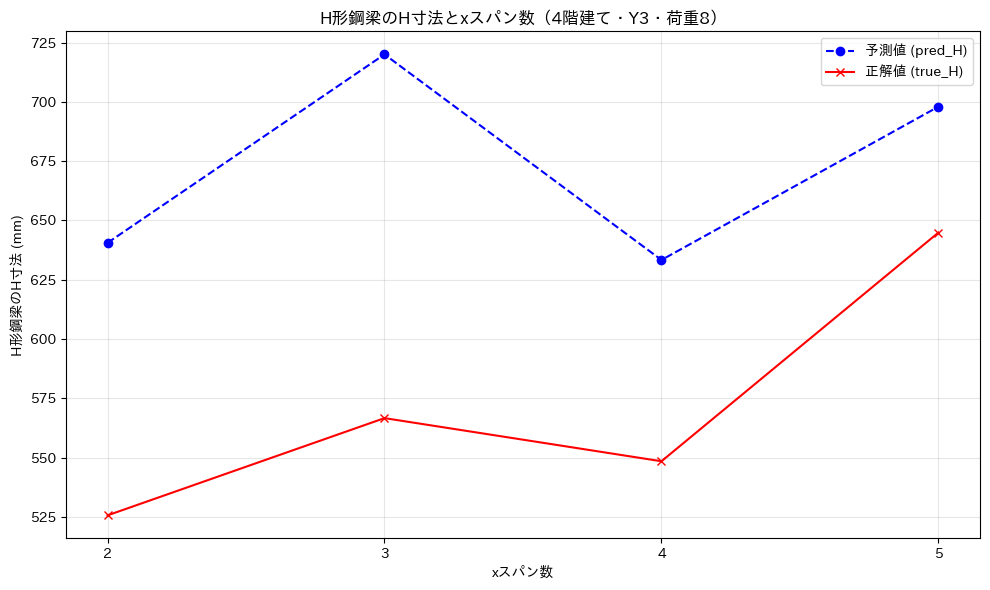

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:

import os
import re
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# ============================================================
# 1. 保存先ディレクトリ
# ============================================================
save_dir = '/content/drive/MyDrive/research/DNN/Graphs'
os.makedirs(save_dir, exist_ok=True)

# ============================================================
# 2. file_name から建物の条件を抽出
#    例: 0006_4階_X2_Y3_荷重8.csv
# ============================================================
df = predictions.copy()

pattern = (
    r'(?P<id>\d+)_'
    r'(?P<floors>\d+)階_'
    r'X(?P<x_spans>\d+)_'
    r'Y(?P<y_spans>\d+)_'
    r'荷重(?P<load>\d+)'
)

extracted = df['file_name'].str.extract(pattern)

df['building_id'] = extracted['id']
df['階数'] = pd.to_numeric(extracted['floors'], errors='coerce')
df['xスパン数'] = pd.to_numeric(extracted['x_spans'], errors='coerce')
df['yスパン数'] = pd.to_numeric(extracted['y_spans'], errors='coerce')
df['荷重'] = pd.to_numeric(extracted['load'], errors='coerce')

# ============================================================
# 3. H形鋼の梁だけを抽出
# ============================================================
df_h = df[
    (df['section_type'] == 'h') &
    (df['slot'].str.startswith('beam:', na=False))
].copy()

# H寸法が欠損しているデータを除外
df_h = df_h.dropna(
    subset=['xスパン数', 'pred_H', 'true_H']
)

# ============================================================
# 4. 比較する条件を指定
#
# 以下は例です。
# 実際に比較したい建物条件に変更してください。
# ============================================================
target_floors = 4
target_y_spans = 3
target_load = 8

df_plot = df_h[
    (df_h['階数'] == target_floors) &
    (df_h['yスパン数'] == target_y_spans) &
    (df_h['荷重'] == target_load)
].copy()

if df_plot.empty:
    raise ValueError(
        '指定条件に一致するデータがありません。'
        '階数・Yスパン数・荷重を確認してください。'
    )

# ============================================================
# 5. xスパン数以外の条件を固定するため、
#    同じ建物ID・階・梁位置を比較対象にする
#
# ここでは、同じ階の同じ梁位置を比較します。
# ============================================================
target_floor = '2FL'

df_plot = df_plot[
    df_plot['slot'].str.startswith(
        f'beam:{target_floor}:',
        na=False
    )
].copy()

if df_plot.empty:
    raise ValueError(
        f'{target_floor} の梁データがありません。'
        'target_floor を確認してください。'
    )

# ============================================================
# 6. xスパン数ごとの H 寸法を集計
#
# 同じ xスパン数に複数の梁がある場合、
# 梁の H 寸法の平均値を計算します。
# ============================================================
summary = (
    df_plot
    .groupby('xスパン数', as_index=False)
    .agg(
        pred_H=('pred_H', 'mean'),
        true_H=('true_H', 'mean'),
        pred_count=('pred_H', 'count'),
        true_count=('true_H', 'count')
    )
    .sort_values('xスパン数')
)

# ============================================================
# 7. グラフの描画
# ============================================================
graph_title = (
    f'H形鋼梁のH寸法とxスパン数'
    f'（{target_floors}階建て・'
    f'Y{target_y_spans}・荷重{target_load}）'
)

plt.figure(figsize=(10, 6))

plt.plot(
    summary['xスパン数'],
    summary['pred_H'],
    marker='o',
    linestyle='--',
    color='blue',
    label='予測値 (pred_H)'
)

plt.plot(
    summary['xスパン数'],
    summary['true_H'],
    marker='x',
    linestyle='-',
    color='red',
    label='正解値 (true_H)'
)

plt.xlabel('xスパン数')
plt.ylabel('H形鋼梁のH寸法 (mm)')
plt.title(graph_title)
plt.xticks(sorted(summary['xスパン数'].unique()))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# ============================================================
# 8. 保存・ダウンロード
# ============================================================
file_name = (
    f'H寸法_xスパン数_'
    f'{target_floors}階_Y{target_y_spans}_'
    f'荷重{target_load}_{target_floor}.png'
)

drive_path = os.path.join(save_dir, file_name)
plt.savefig(drive_path, dpi=300, bbox_inches='tight')

print(f'Google Driveへの保存先: {drive_path}')
print('\n集計結果:')
print(summary.to_string(index=False))

plt.show()

# PCへのダウンロード
files.download(drive_path)


##梁のDと荷重のグラフ

In [68]:
# 条件を満たすデータの件数
print('対象データ数:', len(df_plot))

# 建物IDごとの荷重の種類数
print(
    df_plot.groupby('building_id')['荷重']
    .agg(['count', 'nunique'])
    .sort_values('nunique')
)

# 荷重の種類
print('荷重一覧:', sorted(df_plot['荷重'].dropna().unique()))

# 建物IDごとに存在する荷重
print(
    df_plot.groupby('building_id')['荷重']
    .apply(lambda s: sorted(s.unique()))
)

対象データ数: 0
Empty DataFrame
Columns: [count, nunique]
Index: []
荷重一覧: []
Series([], Name: 荷重, dtype: int64)


荷重ごとの集計結果:
 荷重  pred_D     true_D  n
  6   250.0 294.444444  9
  7   250.0 323.529412 17
  8   250.0 377.777778  9

比較に使用した建物ID:
['0131', '0173', '0185', '0215', '0259', '0263', '0321', '0332', '0352', '0423', '0427', '0459', '0515', '0577', '0581', '0626', '0662', '0676', '0680', '0690', '0757', '0798', '0843', '0886', '0926', '0944', '1000', '1018', '1042', '1108', '1126', '1153', '1435', '1441', '1461']

Google Driveへの保存先: /content/drive/MyDrive/research/DNN/Graphs/柱D寸法_荷重_3階_X2_Y3_2FL_C1.png


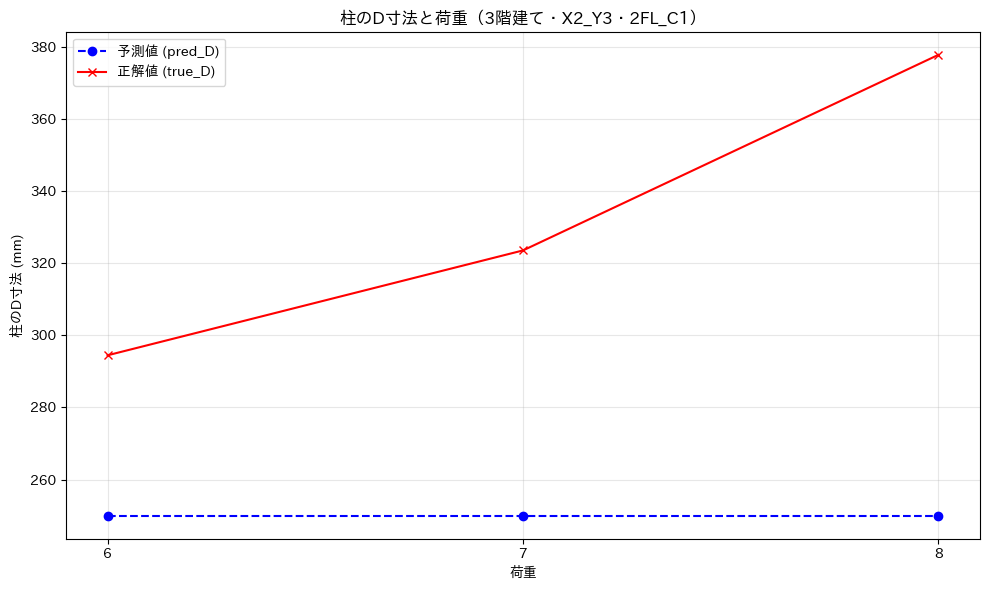

画像ファイル: /content/drive/MyDrive/research/DNN/Graphs/柱D寸法_荷重_3階_X2_Y3_2FL_C1.png
ファイルサイズ: 138,034 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [74]:

import os
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# ============================================================
# 1. 保存先ディレクトリ
# ============================================================
save_dir = '/content/drive/MyDrive/research/DNN/Graphs'
os.makedirs(save_dir, exist_ok=True)

# ============================================================
# 2. file_name から建物条件を抽出
#    例: 0006_3階_X2_Y3_荷重8.csv
# ============================================================
df = predictions.copy()

pattern = (
    r'(?P<id>\d+)_'
    r'(?P<floors>\d+)階_'
    r'X(?P<x_spans>\d+)_'
    r'Y(?P<y_spans>\d+)_'
    r'荷重(?P<load>\d+)'
)

extracted = df['file_name'].str.extract(pattern)

df['building_id'] = extracted['id']
df['階数'] = pd.to_numeric(extracted['floors'], errors='coerce')
df['xスパン数'] = pd.to_numeric(extracted['x_spans'], errors='coerce')
df['yスパン数'] = pd.to_numeric(extracted['y_spans'], errors='coerce')
df['荷重'] = pd.to_numeric(extracted['load'], errors='coerce')

# ============================================================
# 3. 角形鋼管柱のデータを抽出
# ============================================================
df_col = df[
    (df['section_type'] == 'box') &
    (df['slot'].str.startswith('column:', na=False))
].copy()

# 荷重・予測D寸法・正解D寸法が存在するデータに限定
df_col = df_col.dropna(
    subset=['荷重', 'pred_D', 'true_D']
)

# ============================================================
# 4. 荷重以外の条件を指定
# ============================================================
target_floors = 3
target_x_spans = 2
target_y_spans = 3
target_floor = '2FL'
target_column = 'C1'

df_plot = df_col[
    (df_col['階数'] == target_floors) &
    (df_col['xスパン数'] == target_x_spans) &
    (df_col['yスパン数'] == target_y_spans) &
    (
        df_col['slot']
        == f'column:{target_floor}:{target_column}'
    )
].copy()

if df_plot.empty:
    raise ValueError(
        '指定条件に一致するデータがありません。'
        '階数・X/Yスパン数・柱位置を確認してください。'
    )

# ============================================================
# 5. 荷重ごとにD寸法を集計
# ============================================================
summary = (
    df_plot.groupby('荷重', as_index=False)
    .agg(
        pred_D=('pred_D', 'mean'),
        true_D=('true_D', 'mean'),
        n=('pred_D', 'count')
    )
    .sort_values('荷重')
)

if summary.empty:
    raise ValueError('集計対象がありません。')

print('荷重ごとの集計結果:')
print(summary.to_string(index=False))

print('\n比較に使用した建物ID:')
print(sorted(df_plot['building_id'].dropna().unique()))

# ============================================================
# 6. グラフタイトル
# ============================================================
graph_title = (
    f'柱のD寸法と荷重'
    f'（{target_floors}階建て・'
    f'X{target_x_spans}_Y{target_y_spans}・'
    f'{target_floor}_{target_column}）'
)

# ============================================================
# 7. グラフの描画
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    summary['荷重'],
    summary['pred_D'],
    marker='o',
    linestyle='--',
    color='blue',
    label='予測値 (pred_D)'
)

ax.plot(
    summary['荷重'],
    summary['true_D'],
    marker='x',
    linestyle='-',
    color='red',
    label='正解値 (true_D)'
)

ax.set_xlabel('荷重')
ax.set_ylabel('柱のD寸法 (mm)')
ax.set_title(graph_title)
ax.set_xticks(sorted(summary['荷重'].unique()))
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

# ============================================================
# 8. Google Drive に保存
# ============================================================
file_name = (
    f'柱D寸法_荷重_'
    f'{target_floors}階_X{target_x_spans}_'
    f'Y{target_y_spans}_{target_floor}_{target_column}.png'
)

drive_path = os.path.join(save_dir, file_name)

fig.savefig(
    drive_path,
    dpi=300,
    bbox_inches='tight'
)

print(f'\nGoogle Driveへの保存先: {drive_path}')

# ============================================================
# 9. グラフを表示してPCへダウンロード
# ============================================================
plt.show()
# 画像ファイルを閉じる前に保存済みであることを確認
if os.path.exists(drive_path):
    print(f'画像ファイル: {drive_path}')
    print(f'ファイルサイズ: {os.path.getsize(drive_path):,} bytes')

    # Google ColabからローカルPCへダウンロード
    files.download(drive_path)
else:
    raise FileNotFoundError(
        f'画像ファイルが見つかりません: {drive_path}'
    )